# ORCHID quickstart: one system, from the release to ESPEI

This notebook queries the Cu–Zr system in the ORCHID release, filters the values (accepted, evidence class,
reader agreement), plots experimental against DFT formation enthalpies, and exports ESPEI datasets for one CALPHAD
description. It reads the release at a pinned commit:

* `ORCHID_DATA=/path/to/orchid-data` (a local checkout at that commit), or
* nothing: files are downloaded from the pinned commit of github.com/orchid-calphad/orchid-data and cached, or
* `ORCHID_DATA=sample-release` (relative to this folder): the Cu–Zr slice shipped with this example, for offline
  use. It gives the same outputs, because everything below is restricted to Cu–Zr.

Values are **Version 1, machine-extracted**: check a value against its paper (DOI) before relying on it, and cite the
original source of every value you use.

In [1]:
import os, sys, json, shutil, csv, io
from pathlib import Path
import pandas as pd
sys.path.insert(0, str(Path.cwd().parent / "common"))
import orchid_data, figstyle as S
import matplotlib.pyplot as plt

RELEASE = "c3d9781c26f72baaad64dd2b6aa6126ba487659e"     # orchid-data commit (v2026.10, 2026-10-24)
OUT = Path(os.environ.get("QUICKSTART_OUT", "figures"))
OUT.mkdir(exist_ok=True)
SYSTEM = "CU-ZR"
print("data from", os.environ.get("ORCHID_DATA") or f"download of commit {RELEASE[:10]}")

data from sample-release


## 1. Query a system from the Parquet release

In [2]:
lv = pd.read_parquet(orchid_data.path("parquet/literature_values.parquet", RELEASE))
cz = lv[lv["system"] == SYSTEM]
print(len(cz), "Cu-Zr values")
cz.groupby(["property", "evidence_class"]).size().unstack(fill_value=0).sort_values("experimental", ascending=False).head(10)

683 Cu-Zr values


evidence_class,dft,experimental,model,unspecified
property,,,,
INVARIANT_TEMPERATURE,0,223,168,30
HM_FORM,15,31,23,0
TRANSITION_TEMPERATURE,0,22,23,4
ACR_CU,0,21,21,0
ACR_ZR,0,21,21,0
PHASE_COMPOSITION,0,14,11,0
LATTICE_A,0,6,0,1
SM_FORM,0,6,6,0
LATTICE_C,0,4,0,0


## 2. Filter: accepted, experimental, read by more than one reader

`accepted` is the release's acceptance after reader agreement and the checks; `evidence_class` separates
experimental values from values calculated with a model, DFT and unspecified ones; `reader_agreement` is
`multi_reader` when independent readers agreed.

In [3]:
sel = cz[cz["accepted"] & (cz["evidence_class"] == "experimental") & (cz["reader_agreement"] == "multi_reader")]
hf = sel[sel["property"] == "HM_FORM"]
print(len(sel), "accepted multi-reader experimental values;", len(hf), "formation enthalpies")
hf[["phases", "value", "unit", "sigma_printed", "sigma_effective", "temperature_K", "method", "paper_citation", "page"]].sort_values("value").head(12)

356 accepted multi-reader experimental values; 31 formation enthalpies


,phases,value,unit,sigma_printed,sigma_effective,temperature_K,method,paper_citation,page
219,[Cu51Zr14],-25.200,kJ/mol-atom,NaN,3.500,298.15,None,"M. A. Turchanin, P. G. Agraval, A. R. Abdulov,...",10
679,[CuZr],-24.400,kJ/mol-atom,NaN,3.500,298.15,None,"K. J. Zeng, M. Hämäläinen, H. L. Lukas, A new ...",1
154,[CuZr],-24.400,kJ/mol-atom,0.960,8.749,298.15,None,"M. A. Turchanin, P. G. Agraval, A. R. Abdulov,...",10
94,[CuZr-B2],-24.400,kJ/mol-atom,NaN,3.500,298.15,None,"S.H. Zhou, R.E. Napolitano, Phase stability fo...",3
458,[Cu51Zr14-β],-24.300,kJ/mol-atom,NaN,3.500,298.15,None,"S.H. Zhou, R.E. Napolitano, Phase stability fo...",3
323,[CuZr],-24.000,kJ/mol-atom,2.000,8.749,298.15,None,"M. A. Turchanin, P. G. Agraval, A. R. Abdulov,...",10
381,[Cu5Zr],-23.800,kJ/mol-atom,NaN,3.500,298.15,None,"M. A. Turchanin, P. G. Agraval, A. R. Abdulov,...",10
482,[Cu10Zr7],-22.900,kJ/mol-atom,NaN,3.500,298.15,None,"M. A. Turchanin, P. G. Agraval, A. R. Abdulov,...",10
139,[Cu10Zr7],-20.272,kJ/mol-atom,0.259,5.630,1123.00,None,"M. A. Turchanin, P. G. Agraval, A. R. Abdulov,...",10
605,[CuZr2],-17.300,kJ/mol-atom,NaN,3.500,298.15,None,"K. J. Zeng, M. Hämäläinen, H. L. Lukas, A new ...",1


## 3. Experiment vs DFT (ORCHID Dataset 4)

Each experimental formation enthalpy is paired with the matched Materials Project and OQMD entries
(`dft_parity`). Filled symbols: experimental values in the calibration's default subset; open: values calculated with
a model in the source.

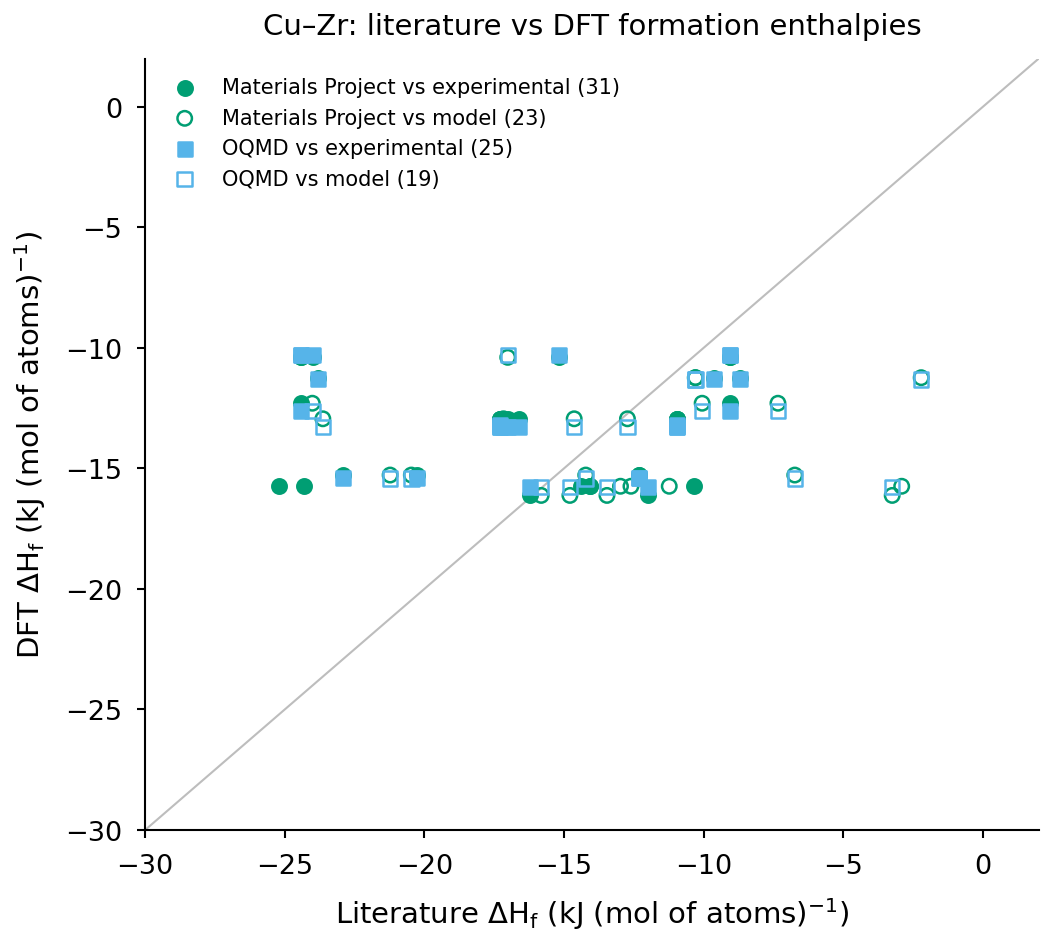

In [4]:
dp = pd.read_parquet(orchid_data.path("parquet/dft_parity.parquet", RELEASE))
d = dp[(dp["system"] == SYSTEM) & dp["accepted"]]
fig, ax = plt.subplots(figsize=(89 * S.mm, 80 * S.mm), constrained_layout=True)
lo, hi = -30, 2
ax.plot([lo, hi], [lo, hi], color=S.grey_m, lw=0.5, zorder=0)
for src in ("mp", "oqmd"):
    for ev, filled in (("experimental", True), ("model", False)):
        q = d[(d["dft_source"] == src) & (d["evidence_class"] == ev)]
        ax.scatter(q["lit_kJ_per_mol_atom"], q["dft_kJ_per_mol_atom"], s=12, marker="o" if src == "mp" else "s",
                   facecolors=S.src[src] if filled else "none", edgecolors=S.src[src], linewidths=0.6,
                   label=f"{S.src_label[src]} vs {ev} ({len(q)})")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("Literature $\\Delta H_f$ (" + S.unit_kja + ")"); ax.set_ylabel("DFT $\\Delta H_f$ (" + S.unit_kja + ")")
ax.legend(fontsize=5, loc="upper left")
ax.set_title("Cu–Zr: literature vs DFT formation enthalpies", fontsize=7)
png, pdf = S.save(fig, OUT / "cuzr_exp_vs_dft")
from IPython.display import Image
Image(png, width=420)

In [5]:
res = d[d["default_subset"]].groupby("dft_source")["residual_kJ_per_mol_atom"].describe()[["count", "mean", "50%", "std"]]
res

,count,mean,50%,std
dft_source,,,,
mp,31.0,2.785935,0.080,6.064621
oqmd,25.0,3.032800,3.326,6.134393


## 4. Export ESPEI datasets for one description

The ESPEI datasets (`espei/`) are written in the phase names of a specific TDB. Here: the experimental and
invariant-table datasets of Cu–Zr for the SGTE description `CuZr-94Zen-LB.tdb` (Zeng et al. 1994), leaving out
datasets tagged `single_reader`. The selection uses `espei/index.csv` (file names start with the TDB name); the files are copied unchanged, with an
ESPEI input skeleton. With ESPEI installed, `load_datasets` checks them.

In [6]:
idx = pd.read_csv(orchid_data.path("espei/index.csv", RELEASE))
named = idx["path"].str.rsplit("/", n=1).str[-1].str.startswith("CuZr-94Zen-LB.")   # datasets are named after their TDB
pick = idx[(idx["system"] == SYSTEM) & named & idx["folder"].isin(["experimental", "invariants"])
           & ~idx["tags"].fillna("").str.split(";").apply(lambda t: "single_reader" in t)]
export = Path(os.environ.get("QUICKSTART_EXPORT", "export")) / "CuZr-94Zen-LB"
shutil.rmtree(export, ignore_errors=True); (export / "datasets").mkdir(parents=True)
for p in pick["path"]:
    shutil.copy(orchid_data.path("espei/" + p, RELEASE), export / "datasets" / p.replace("/", "__"))
(export / "espei-in.yaml").write_text("system:\n  phase_models: phases.json   # your phase models for CuZr-94Zen-LB\n  datasets: datasets\n"
                                      "  tags:\n    model: {disabled: true}\n")
summary = pick.groupby(["folder", "output"]).size().rename("datasets")
print(len(pick), "datasets exported to", export)
summary

10 datasets exported to export/CuZr-94Zen-LB


folder        output
experimental  ZPF       7
invariants    ZPF       3
Name: datasets, dtype: int64

In [7]:
try:
    from espei.datasets import load_datasets, recursive_glob
    ds = load_datasets(sorted(recursive_glob(str(export / "datasets"))))
    print("ESPEI load_datasets:", len(ds.all()), "datasets loaded")
except ImportError:
    print("ESPEI not installed: pip install espei==0.9.1 to check the export with load_datasets")

ESPEI load_datasets: 10 datasets loaded


## Citing

Cite the ORCHID data release (`CITATION.cff` of orchid-data; DOIs on Zenodo) and the original source of every value
(`paper_citation`, `paper_doi`; for ESPEI datasets `reference` and `bibtex`). ORCHID data: CC BY 4.0; Materials
Project and OQMD data: CC BY 4.0.